# Data Lake services: discovery, compute and hooks

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/26-data-lake.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/26-data-lake.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `845624c2a2ef242bdd4006a61dbd7eac98793579a73e0ffd52ca30d0fd87a1d7`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Data Lake services: discovery, compute and hooks

**Lesson 26 · Original synthetic data · Independent educational project**

## Objectives

Connect HDA/STAC discovery concepts with a local manifest; validate an event-driven processing contract.

[Previous](25-earthkit-export.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/26-data-lake.ipynb) · [Next](27-ai-validation.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=26-data-lake.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

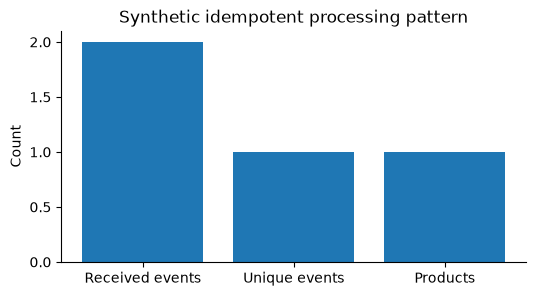

In [2]:
catalog = [
    {"id": "synthetic-temperature", "variable": "temperature", "units": "K", "bbox": [-180,-84,180,84], "license": "CC BY 4.0"},
    {"id": "synthetic-rain", "variable": "precipitation", "units": "mm day-1", "bbox": [-180,-84,180,84], "license": "CC BY 4.0"}]
selected = [item for item in catalog if item["variable"] == "temperature"]
assert len(selected) == 1
events = [{"event_id": "demo-1", "item": selected[0]["id"]}, {"event_id": "demo-1", "item": selected[0]["id"]}]
seen, products = set(), []
for event in events:
    if event["event_id"] in seen: continue
    seen.add(event["event_id"])
    cube = lab.synthetic_cube()
    products.append(float(lab.global_mean(cube["temperature"][0], cube["lat"])))
assert len(products) == 1, "Duplicate delivery must not duplicate products"
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Received events", "Unique events", "Products"], [len(events),len(seen),len(products)])
ax.set(ylabel="Count", title="Synthetic idempotent processing pattern")
plt.show()

## Exercise

Add a second unique event and test product count. Extend the local manifest with a retrieval timestamp and an explicit asset media type.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

The Data Lake documentation describes HDA for harmonized access and STAC discovery, plus services including Islet, Stack and Hook for connected user workflows. Consult each service's current interface and entitlement requirements. This plain Python manifest and duplicate-event check are conceptual exercises, not valid STAC records, a Hook client or cloud deployment.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine-data-lake-docs.data.destination-earth.eu/en/latest/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).